# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

**Question.** An agricultural extension officer wants to compare the rainfall regimes of Kampala, Gulu and Mbarara and advise farmers which crops suit which months. This notebook builds a `Region` and a `CropRule` class, corrects last year's flawed cosine-similarity method, compares regions with three measures, detects rainy seasons automatically and ends with a farmer advisory.

**Organisation.** Reusable logic is in `src/` (`rainfall.py`, `similarity.py`, `seasons.py`, `nasa_power.py`, `rainfall_plotting.py`); this notebook imports it and interprets the results. It runs with *Restart & Run All* and does **not** need internet access: the real-data extension at the end reads a saved NASA POWER CSV if one is present in `data/` (see that section).

**Data.** Monthly rainfall in mm, January to December, is the supplied **illustrative** data. Crop thresholds come from cited sources and are explained in Task 2.

In [1]:
# Locate the repo root (the folder containing src/) so imports work wherever Jupyter was launched.
import os, sys, math
from pathlib import Path
for _root in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (_root / "src" / "rainfall.py").exists():
        os.chdir(_root)
        sys.path.insert(0, str(_root))
        break
else:
    raise FileNotFoundError(
        "Cannot find the 'src/' folder. Open this notebook from inside the project "
        "repository (keep src/ next to the notebook)."
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import find_peaks
from scipy.spatial.distance import cosine as scipy_cosine_distance

from src.rainfall import Region, CropRule, default_crops, MONTHS, DROUGHT, WATERLOGGING
from src.similarity import (cosine_similarity, cosine_similarity_matrix,
                            pearson_matrix, euclidean_distance_matrix)
from src.seasons import detect_rainy_seasons, classify_regime, peak_count_sweep
from src.nasa_power import fetch_nasa_monthly, load_nasa_monthly, monthly_matrix
from src.rainfall_plotting import (plot_rainfall_lines, plot_suitability_heatmap,
                                   plot_similarity_matrices, plot_monthly_boxplots)

RAINFALL = {   # supplied illustrative monthly totals, mm (Jan..Dec)
    "Kampala": [120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130],
    "Gulu":    [8, 25, 75, 160, 190, 145, 170, 215, 175, 150, 60, 15],
    "Mbarara": [70, 85, 120, 140, 90, 25, 20, 55, 100, 125, 120, 90],
}
PROMINENCE_FRACTION = 0.30      # a rainy-season peak must stand out by >= 30% of the wettest month
NASA_CSV = "data/nasa_power_monthly_rainfall_2014_2023.csv"
FETCH_NASA = False              # True: download the CSV from NASA POWER if missing (needs internet)

regions = [Region(name, values) for name, values in RAINFALL.items()]
names = [r.name for r in regions]
crops = default_crops()
os.makedirs("figures", exist_ok=True); os.makedirs("data", exist_ok=True)
pd.options.display.float_format = "{:,.2f}".format
print(regions)

[Region('Kampala', annual=1,600 mm), Region('Gulu', annual=1,388 mm), Region('Mbarara', annual=1,040 mm)]


## Task 1 — `Region` class

`Region` stores the 12 monthly totals as a NumPy array, validates them (exactly 12 values, finite, non-negative) and provides the annual total, the mean, the wettest and driest month and the coefficient of variation (CV = standard deviation ÷ mean of the 12 months, population formula because the 12 months are the complete annual cycle).

In [2]:
rows = []
for r in regions:
    wet, dry = r.wettest_month(), r.driest_month()
    rows.append({"Region": r.name, "Annual total (mm)": r.annual_total(), "Mean per month (mm)": r.monthly_mean(),
                 "Wettest month": f"{wet[0]} ({wet[1]:.0f} mm)", "Driest month": f"{dry[0]} ({dry[1]:.0f} mm)",
                 "CV (%)": r.coefficient_of_variation() * 100})
display(pd.DataFrame(rows).set_index("Region"))

,Annual total (mm),Mean per month (mm),Wettest month,Driest month,CV (%)
Region,,,,,
Kampala,"1,600.00",133.33,May (220 mm),Sep (60 mm),37.17
Gulu,"1,388.00",115.67,Aug (215 mm),Jan (8 mm),61.42
Mbarara,"1,040.00",86.67,Apr (140 mm),Jul (20 mm),42.48


Kampala is the wettest region (1,600 mm a year) and Mbarara the driest (1,040 mm). Gulu has the highest CV (61 %): its rain is strongly concentrated in April–October with an almost dry January (8 mm), whereas Kampala's rainfall is spread more evenly through the year.

## Task 2 — `CropRule` class and the crop thresholds

**Method.** Each crop has a *seasonal* water need from a cited source. Spreading that need evenly over the crop cycle gives a *monthly* band: a month below the band is a **drought risk**, a month above it a **waterlogging risk**, and a month inside it is **good** for that crop.

| Crop | Seasonal need | Cycle | Monthly band | Source |
|---|---|---|---|---|
| Maize | 500–800 mm | 4 months (assumed) | 125–200 mm | FAO: a medium-maturity grain maize crop needs 500–800 mm; Brouwer & Heibloem (1986), *Irrigation Water Management: Irrigation Water Needs*, FAO Training Manual No. 3, Table 2 |
| Beans | 300–500 mm | 3 months (assumed) | 100–167 mm | FAO crop water information for dry beans: 300–500 mm for a 60–120-day crop; same FAO manual, Table 2 |
| Coffee | 1,200–1,800 mm per year | 12 months | 100–150 mm | Annual rainfall of 1,200–1,800 mm for Robusta (Brunini et al., ASIC 2025 poster); a general range, not Uganda-specific, so the UCDA *Robusta Coffee Handbook* (2019), section 2.4, should be checked |

The cycle lengths are my assumptions: 4 months for medium-maturity maize and 3 months (about 90 days) for beans, inside FAO's 60–120-day range.

In [3]:
spec = pd.DataFrame([{"crop": c.name, "seasonal need (mm)": f"{c.seasonal_min_mm:,.0f}-{c.seasonal_max_mm:,.0f}",
                      "cycle (months)": c.cycle_months,
                      "good monthly band (mm)": f"{c.monthly_min_mm:.0f}-{c.monthly_max_mm:.0f}"} for c in crops]).set_index("crop")
display(spec)

rows = []
for r in regions:
    for crop in crops:
        for month, mm, label in zip(MONTHS, r.rainfall, crop.classify_region(r)):
            rows.append({"region": r.name, "crop": crop.name, "month": month, "rainfall_mm": mm, "classification": label})
classification = pd.DataFrame(rows)
classification.to_csv("data/crop_suitability_classification.csv", index=False)   # all 108 classifications

code = {DROUGHT: "D", WATERLOGGING: "W"}
classification["code"] = classification["classification"].map(lambda s: code.get(s, "G"))
print("Month-by-month classification (G = good for the crop, D = drought risk, W = waterlogging risk)")
display(classification.pivot_table(index=["region", "crop"], columns="month", values="code", aggfunc="first")[list(MONTHS)])

counts = classification.assign(kind=classification["code"].map({"G": "Good", "D": "Drought risk", "W": "Waterlogging risk"})
                              ).pivot_table(index=["region", "crop"], columns="kind", values="month", aggfunc="count", fill_value=0)
display(counts[["Good", "Drought risk", "Waterlogging risk"]])
print("Example of the full labels:"); display(classification[(classification.region == "Kampala") & (classification.crop == "Maize")][["month", "rainfall_mm", "classification"]].T)

,seasonal need (mm),cycle (months),good monthly band (mm)
crop,,,
Maize,500-800,4,125-200
Beans,300-500,3,100-167
Coffee,"1,200-1,800",12,100-150


Month-by-month classification (G = good for the crop, D = drought risk, W = waterlogging risk)


month          Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec
region  crop                                                  
Gulu    Beans    D   D   D   G   W   G   W   W   W   G   D   D
        Coffee   D   D   D   W   W   G   W   W   W   G   D   D
        Maize    D   D   D   G   G   G   G   W   G   G   D   D
Kampala Beans    G   G   W   W   W   W   D   D   D   G   G   G
        Coffee   G   G   W   W   W   W   D   D   D   G   G   G
        Maize    D   G   G   G   W   G   D   D   D   D   D   G
Mbarara Beans    D   D   G   G   D   D   D   D   G   G   G   D
        Coffee   D   D   G   G   D   D   D   D   G   G   G   D
        Maize    D   D   D   G   D   D   D   D   D   G   D   D

kind            Good  Drought risk  Waterlogging risk
region  crop                                         
Gulu    Beans      3             5                  4
        Coffee     2             5                  5
        Maize      6             5                  1
Kampala Beans      5             3                  4
        Coffee     5             3                  4
        Maize      5             6                  1
Mbarara Beans      5             7                  0
        Coffee     5             7                  0
        Maize      2            10                  0

Example of the full labels:


,0,1,2,3,4,5,6,7,8,9,10,11
month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
rainfall_mm,120.00,140.00,180.00,200.00,220.00,180.00,90.00,70.00,60.00,100.00,110.00,130.00
classification,Drought risk,Good for maize,Good for maize,Good for maize,Waterlogging risk,Good for maize,Drought risk,Drought risk,Drought risk,Drought risk,Drought risk,Good for maize


**What the classification shows.**
- **Kampala** has 5 good months for each crop. Its wet March–June is a waterlogging risk for beans and coffee (4 months), and July–September is a short drought season.
- **Gulu** has a long dry season (November–March, 5 drought months for every crop). Its peak rains (May and July–September) exceed the bean and coffee bands (4–5 waterlogging months), so maize copes best there (6 good months, April–July, September and October).
- **Mbarara** has no waterlogging months but is drought-prone: 10 of 12 months are below maize's 125 mm, and 7 of 12 for beans and coffee.
- **Coffee** is perennial, so the annual total matters most: Kampala (1,600 mm) and Gulu (1,388 mm) lie inside the 1,200–1,800 mm band, but Mbarara (1,040 mm) is below it. That agrees with a Uganda yield-gap study which found that seasonal rainfall shortage was a significant limitation to Arabica production in the south-west (*Evaluating coffee yield gaps and important biotic, abiotic, and management factors limiting coffee production in Uganda*, CGIAR CGSpace).

**Limitations of these thresholds.** They are screening rules, not validated crop models: they treat all rain as if it reached the crop (no runoff, soil storage or effective-rainfall fraction), spread the water need evenly across the cycle (real need peaks mid-season), and a "waterlogging risk" depends on soil drainage as much as on rainfall. Coffee also needs a dry spell to flower, so a "drought" month is less harmful for coffee than for maize.

## Task 3 — Correcting the flawed cosine-similarity method

**What was wrong.** Last year's question asked for similarity using `math.cos()`. `math.cos(x)` takes **one number** interpreted as an **angle in radians** and returns its cosine. It cannot take a rainfall vector (it raises an error), and applying it to some derived number gives a value that has nothing to do with how alike two regions are. Cosine *similarity* is the cosine of the **angle between two vectors**:

$$\cos\theta = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$$

In [4]:
kampala, mbarara = regions[0].rainfall, regions[2].rainfall

try:
    math.cos(kampala)
except TypeError as e:
    print("math.cos(vector) fails:", e)
print("math.cos(a.b) is just the cosine of a huge angle, meaningless as similarity:", round(math.cos(np.dot(kampala, mbarara)), 4))

mine = cosine_similarity(kampala, mbarara)                    # dot product / product of norms (NumPy)
scipy_value = 1 - scipy_cosine_distance(kampala, mbarara)     # SciPy returns the distance, so similarity = 1 - distance
print(f"\nCorrect cosine similarity Kampala-Mbarara: mine = {mine:.6f}, SciPy = {scipy_value:.6f}")

X = np.array([r.rainfall for r in regions])
cos_m = cosine_similarity_matrix(X)
for i in range(len(regions)):
    for j in range(len(regions)):
        assert np.isclose(cos_m[i, j], 1 - scipy_cosine_distance(X[i], X[j]))
print("Verified against scipy.spatial.distance.cosine for all 9 pairs.")

math.cos(vector) fails: only 0-dimensional arrays can be converted to Python scalars
math.cos(a.b) is just the cosine of a huge angle, meaningless as similarity: 0.9421

Correct cosine similarity Kampala-Mbarara: mine = 0.891250, SciPy = 0.891250
Verified against scipy.spatial.distance.cosine for all 9 pairs.


## Task 4 — Cosine similarity, Pearson correlation and Euclidean distance

COSINE SIMILARITY (1 = same direction)


,Kampala,Gulu,Mbarara
Kampala,1.00,0.79,0.89
Gulu,0.79,1.00,0.75
Mbarara,0.89,0.75,1.00


PEARSON CORRELATION (1 = same seasonal shape)


,Kampala,Gulu,Mbarara
Kampala,1.00,-0.07,0.21
Gulu,-0.07,1.00,-0.17
Mbarara,0.21,-0.17,1.00


EUCLIDEAN DISTANCE (mm over the 12-month vector)


,Kampala,Gulu,Mbarara
Kampala,0.00,315.27,250.40
Gulu,315.27,0.00,312.80
Mbarara,250.40,312.80,0.00


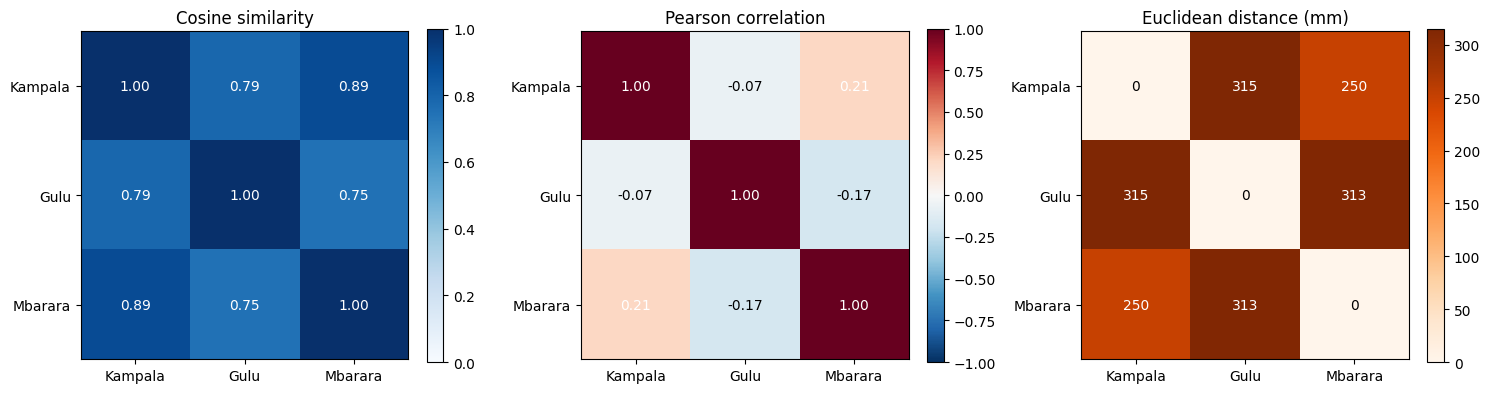

A region with exactly 3x Kampala's rain every month:  cosine = 1.000, Pearson = 1.000, Euclidean distance = 985 mm
Kampala vs Mbarara: cosine = 0.891, yet Kampala has 54% more annual rain


In [5]:
pear_m = pearson_matrix(X)
euc_m = euclidean_distance_matrix(X)
print("COSINE SIMILARITY (1 = same direction)");        display(pd.DataFrame(cos_m, index=names, columns=names))
print("PEARSON CORRELATION (1 = same seasonal shape)"); display(pd.DataFrame(pear_m, index=names, columns=names))
print("EUCLIDEAN DISTANCE (mm over the 12-month vector)"); display(pd.DataFrame(euc_m, index=names, columns=names))
fig = plot_similarity_matrices(names, cos_m, pear_m, euc_m)
fig.savefig("figures/rainfall_similarity_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

wet3 = 3 * kampala
print(f"A region with exactly 3x Kampala's rain every month:  cosine = {cosine_similarity(kampala, wet3):.3f}, "
      f"Pearson = {np.corrcoef(kampala, wet3)[0, 1]:.3f}, Euclidean distance = {np.linalg.norm(kampala - wet3):,.0f} mm")
print(f"Kampala vs Mbarara: cosine = {cos_m[0, 2]:.3f}, yet Kampala has {regions[0].annual_total() / regions[2].annual_total() - 1:.0%} more annual rain")

**Why cosine similarity can call two regions "similar" when one is much wetter.** Cosine compares only the **direction** of the two 12-month vectors, never their length. Multiplying a region's rainfall by any constant leaves its cosine unchanged: a region with three times Kampala's rain in every month scores a perfect **1.000** even though it is 985 mm away in Euclidean distance. In the real data, Kampala and Mbarara score 0.89 although Kampala receives 54 % more rain a year.

Two further points:
- **Rainfall is never negative**, so cosine similarity can only lie between 0 and 1 and is high for almost any pair (0.75–0.89 here), which gives it little power to discriminate.
- **Pearson correlation** removes the mean and the scale and compares the seasonal *shape*. It is near zero or negative (−0.17 to 0.21): the regions' wet and dry months do not line up, a difference that cosine hides.

All three measures agree that **Kampala and Mbarara are the most alike** (cosine 0.89, Pearson 0.21, distance 250 mm). Euclidean distance is the only one of the three that reflects how much wetter one region is, and it puts Gulu about as far from Kampala (315 mm) as from Mbarara (313 mm). Which measure is "right" depends on the question: cosine/Pearson for *timing*, Euclidean for *amount*.

## Task 5 — Automatic rainy-season detection with `scipy.signal.find_peaks`

The 12-month climatology is **circular** (December is followed by January), so it is tiled three times and only peaks in the middle copy are kept. A peak counts as a separate rainy season only if its **prominence** (how far it stands above the surrounding trough) is at least 30 % of the region's wettest month; peaks must be at least 2 months apart. The threshold matters, so a sensitivity check follows.

In [6]:
KNOWN = {"Kampala": "bimodal", "Gulu": "unimodal", "Mbarara": "bimodal"}   # see the references below
rows = []
for r in regions:
    pk = detect_rainy_seasons(r.rainfall, PROMINENCE_FRACTION)
    regime = classify_regime(pk)
    rows.append({"region": r.name, "detected peaks": ", ".join(f"{MONTHS[i]} ({r.rainfall[i]:.0f} mm)" for i in pk),
                 "detected regime": regime, "expected (literature)": KNOWN[r.name],
                 "matches?": "yes" if regime == KNOWN[r.name] else "NO"})
display(pd.DataFrame(rows).set_index("region"))

print("How far each local peak stands above its trough (prominence), tiled circular data:")
for r in regions:
    tiled = np.tile(r.rainfall, 3)
    idx, props = find_peaks(tiled, prominence=0, distance=2)
    mid = [(MONTHS[i - 12], props["prominences"][k]) for k, i in enumerate(idx) if 12 <= i < 24]
    print(f"  {r.name:<8}", [(m, f"{p:.0f} mm = {p / r.rainfall.max():.0%} of max") for m, p in mid])

fractions = [0.02, 0.04, 0.05, 0.10, 0.20, 0.25, 0.30, 0.40, 0.50]
sweep = pd.DataFrame({r.name: peak_count_sweep(r.rainfall, fractions) for r in regions})
sweep.index.name = "prominence threshold (fraction of max)"
display(sweep)

,detected peaks,detected regime,expected (literature),matches?
region,,,,
Kampala,May (220 mm),unimodal,bimodal,NO
Gulu,Aug (215 mm),unimodal,unimodal,yes
Mbarara,"Apr (140 mm), Oct (125 mm)",bimodal,bimodal,yes


How far each local peak stands above its trough (prominence), tiled circular data:
  Kampala  [('May', '160 mm = 73% of max'), ('Dec', '10 mm = 5% of max')]
  Gulu     [('May', '45 mm = 21% of max'), ('Aug', '207 mm = 96% of max')]
  Mbarara  [('Apr', '120 mm = 86% of max'), ('Oct', '55 mm = 39% of max')]


,Kampala,Gulu,Mbarara
prominence threshold (fraction of max),,,
0.02,2,2,2
0.04,2,2,2
0.05,1,2,2
0.10,1,2,2
0.20,1,2,2
0.25,1,1,2
0.30,1,1,2
0.40,1,1,1
0.50,1,1,1


**Expected regimes (literature).** Uganda has a bimodal regime over most of the country, with the main season in March–May and a shorter one in September–November, while the northern parts have a unimodal regime (Basalirwa 1995, as summarised in Kisembe et al. 2018, *Evaluation of rainfall simulations over Uganda in CORDEX regional climate models*, Theoretical and Applied Climatology, doi:10.1007/s00704-018-2643-x). The Uganda National Meteorological Authority likewise describes two main seasons (MAM and SOND), with the northern sector having a third season in June–August that joins them into one long season (Daily Monitor, 2024). So **Kampala and Mbarara should be bimodal and Gulu unimodal**.

**Result.** At the 30 % threshold, **Mbarara is bimodal** (April and October, separated by a very dry June–July) and **Gulu is unimodal** (one long season peaking in August; its May peak is only a 45 mm dip away from the rest of the season, 21 % of the maximum). Both match. **Kampala comes out unimodal, which does not match** the literature.

This mismatch comes from the **supplied data, not the method**: Kampala's illustrative rainfall rises almost continuously from September (60 mm) to May (220 mm), and its only second "peak" (December, 130 mm) is a 10 mm wiggle above January (120 mm), too small to be a separate season. The sensitivity table shows why a threshold must be chosen with care: at a low threshold of 2–4 % **all three regions look bimodal**, because tiny wiggles count as seasons; Gulu and Mbarara are classified as expected for any threshold from 21 % to 39 %, and 30 % lies in the middle of that range. The real-data extension below can be used to check Kampala properly.

## Task 6 — Visualisations

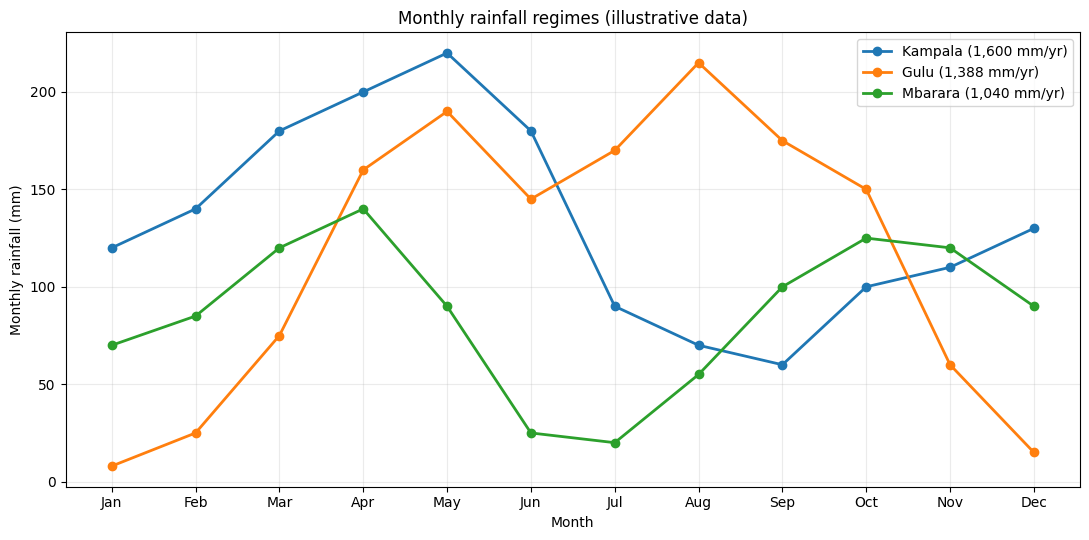

In [7]:
fig = plot_rainfall_lines(regions)
fig.savefig("figures/rainfall_regions_lines.png", dpi=150, bbox_inches="tight")
plt.show()

The line chart shows the three regimes: Kampala's broad rainy period peaking in May, Gulu's single long season (April–October) with an almost dry January, and Mbarara's two peaks (April and October) separated by a deep dry June–July.

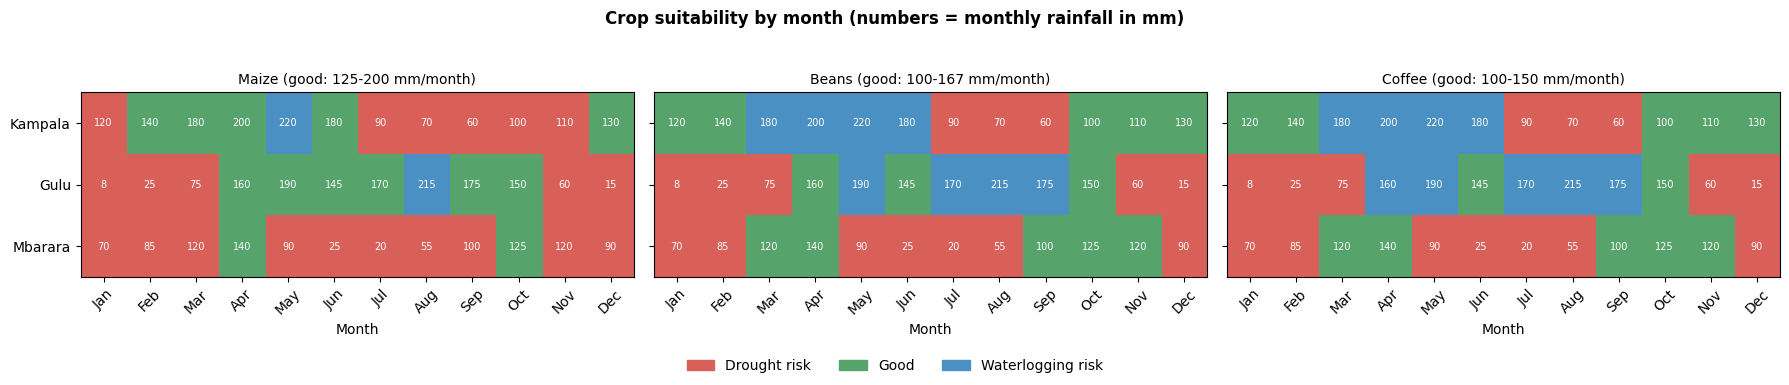

In [8]:
fig = plot_suitability_heatmap(regions, crops)
fig.savefig("figures/rainfall_suitability_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

The heatmap gives the month-by-month verdict for each crop and region; the numbers are the monthly rainfall in mm. It makes the main contrast visible: Mbarara's rows are mostly red (drought risk) with no blue (waterlogging) cells, whereas Kampala has blue cells in its wet March–June.

## Task 7 — Advisory note for Mbarara farmers

The advice rests on a *planting-window* check: for each possible planting month, add up the rain over the whole crop cycle and compare it with the crop's seasonal need (from Task 2).

In [9]:
mb = regions[2]
by_name = {c.name: c for c in crops}
for crop_name in ("Beans", "Maize"):
    crop = by_name[crop_name]
    print(f"{crop_name}: rain over a {crop.cycle_months}-month cycle vs need {crop.seasonal_min_mm:,.0f}-{crop.seasonal_max_mm:,.0f} mm")
    display(pd.DataFrame(crop.planting_windows(mb)).set_index("plant").T)
print(f"Coffee: Mbarara annual rainfall = {mb.annual_total():,.0f} mm vs need 1,200-1,800 mm")

Beans: rain over a 3-month cycle vs need 300-500 mm


plant,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
cycle,Jan-Mar,Feb-Apr,Mar-May,Apr-Jun,May-Jul,Jun-Aug,Jul-Sep,Aug-Oct,Sep-Nov,Oct-Dec,Nov-Jan,Dec-Feb
total_mm,275.00,345.00,350.00,255.00,135.00,100.00,175.00,280.00,345.00,335.00,280.00,245.00
lowest_month_mm,70.00,85.00,90.00,25.00,20.00,20.00,20.00,55.00,100.00,90.00,70.00,70.00
status,deficit,adequate,adequate,deficit,deficit,deficit,deficit,deficit,adequate,adequate,deficit,deficit


Maize: rain over a 4-month cycle vs need 500-800 mm


plant,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
cycle,Jan-Apr,Feb-May,Mar-Jun,Apr-Jul,May-Aug,Jun-Sep,Jul-Oct,Aug-Nov,Sep-Dec,Oct-Jan,Nov-Feb,Dec-Mar
total_mm,415.00,435.00,375.00,275.00,190.00,200.00,300.00,400.00,435.00,405.00,365.00,365.00
lowest_month_mm,70.00,85.00,25.00,20.00,20.00,20.00,20.00,55.00,90.00,70.00,70.00,70.00
status,deficit,deficit,deficit,deficit,deficit,deficit,deficit,deficit,deficit,deficit,deficit,deficit


Coffee: Mbarara annual rainfall = 1,040 mm vs need 1,200-1,800 mm


In [10]:
advisory = (
    "Advisory for Mbarara farmers: grow beans, and plant in March and again in September. "
    "Beans need roughly 300-500 mm of rain over a three-month crop (FAO). In the average year used here, "
    "beans planted in March receive about 350 mm (March-May) and beans planted in September about 345 mm "
    "(September-November), so both fit that range and match the April and October rainy peaks. Plant when the "
    "rains have started, in early March and early September; February and October are acceptable but riskier. "
    "Avoid planting from April to August, when the crop would meet the dry months of June to August (only "
    "20-55 mm a month), and from November to January, when cycle rain (245-280 mm) falls short. "
    "Do not rely on rain-fed maize: even the best four-month "
    "planting (about 435 mm) is below the 500 mm maize needs, so grow maize only with irrigation. Coffee needs "
    "about 1,200-1,800 mm a year and Mbarara's 1,040 mm is below that, so plan mulching or irrigation. "
    "These are screening guidelines from illustrative average rainfall, not a forecast: check local forecasts "
    "and your extension officer."
)
print(advisory)
print(f"\nWord count: {len(advisory.split())} (limit 200)")
assert len(advisory.split()) <= 200

Advisory for Mbarara farmers: grow beans, and plant in March and again in September. Beans need roughly 300-500 mm of rain over a three-month crop (FAO). In the average year used here, beans planted in March receive about 350 mm (March-May) and beans planted in September about 345 mm (September-November), so both fit that range and match the April and October rainy peaks. Plant when the rains have started, in early March and early September; February and October are acceptable but riskier. Avoid planting from April to August, when the crop would meet the dry months of June to August (only 20-55 mm a month), and from November to January, when cycle rain (245-280 mm) falls short. Do not rely on rain-fed maize: even the best four-month planting (about 435 mm) is below the 500 mm maize needs, so grow maize only with irrigation. Coffee needs about 1,200-1,800 mm a year and Mbarara's 1,040 mm is below that, so plan mulching or irrigation. These are screening guidelines from illustrative aver

## Extension — Real rainfall (NASA POWER, 2014–2023) and year-to-year variability

**How this section works.** It reads `data/nasa_power_monthly_rainfall_2014_2023.csv`: 10 years of daily NASA POWER precipitation (`PRECTOTCORR`, mm/day) for the three locations, summed into monthly totals. The notebook does not need internet access to run; if the CSV is missing it prints a message and skips this section. To create the CSV, set `FETCH_NASA = True` in the setup cell and run once with internet access (or copy in an existing file with the same columns: `region, year, month, rainfall_mm`), then commit the CSV with the repository. NASA POWER values are gridded satellite/reanalysis estimates, not rain-gauge records.

In [11]:
if not os.path.exists(NASA_CSV) and FETCH_NASA:
    try:
        fetch_nasa_monthly().to_csv(NASA_CSV, index=False)
        print("Downloaded and saved", NASA_CSV)
    except Exception as e:                       # no internet, API down, ...
        print("Download failed:", type(e).__name__, e)

if not os.path.exists(NASA_CSV):
    nasa = None
    print(f"NASA POWER file not found at '{NASA_CSV}'. Extension skipped: set FETCH_NASA = True (needs internet) "
          "or copy the CSV into data/ and re-run.")
else:
    nasa = load_nasa_monthly(NASA_CSV)
    n_years = nasa.groupby("region")["year"].nunique()
    print("Years of data per region:", {k: int(v) for k, v in n_years.items()})
    fig = plot_monthly_boxplots(nasa, names)
    fig.savefig("figures/nasa_power_monthly_boxplots.png", dpi=150, bbox_inches="tight")
    plt.show()

NASA POWER file not found at 'data/nasa_power_monthly_rainfall_2014_2023.csv'. Extension skipped: set FETCH_NASA = True (needs internet) or copy the CSV into data/ and re-run.


In [12]:
if nasa is not None:
    rows = []
    for r in regions:
        mat = monthly_matrix(nasa, r.name)                      # (years x 12)
        real_mean = mat.mean(axis=0)
        real_regime = classify_regime(detect_rainy_seasons(real_mean, PROMINENCE_FRACTION))
        rows.append({"region": r.name,
                     "real mean annual (mm)": real_mean.sum(),
                     "illustrative annual (mm)": r.annual_total(),
                     "real regime (30% rule)": real_regime,
                     "expected (literature)": KNOWN[r.name],
                     "wettest-month IQR (mm)": np.subtract(*np.percentile(mat[:, real_mean.argmax()], [75, 25]))})
    print("Real-data climatology vs the illustrative data")
    display(pd.DataFrame(rows).set_index("region"))

    beans = by_name["Beans"]
    mat_mb = monthly_matrix(nasa, "Mbarara")
    rows = []
    for m in range(12):
        totals = np.array([beans.cycle_total(Region("Mbarara", year), m) for year in mat_mb])
        rows.append({"plant": MONTHS[m], "median cycle rain (mm)": np.median(totals),
                     "years adequate (%)": np.mean((totals >= beans.seasonal_min_mm) & (totals <= beans.seasonal_max_mm)) * 100})
    print("Mbarara beans: how often each planting month receives 300-500 mm over the 3-month cycle, across the real years")
    display(pd.DataFrame(rows).set_index("plant").T)

**How to read the extension output.**
- **Box plots.** A box much taller than the width of a crop's monthly band means that a single "average" month can badly misclassify a given year, so the month classifications in Task 2 describe *typical* conditions, not a guarantee. Months with the widest boxes are the ones where planting dates carry the most risk.
- **Real vs illustrative climatology.** The table compares the real annual totals and the detected rainy-season regimes with the supplied illustrative data and with the literature, which is the proper check of the Kampala result in Task 5.
- **Planting-window reliability.** The last table turns the advisory into a probability: planting months that are adequate in most of the ten years are safer recommendations than those that are adequate in only a few.

## Sanity checks (hand calculations / second method)

In [13]:
# 1. Cosine similarity: whole matrix equals SciPy's (1 - cosine distance), and the diagonal is 1
for i in range(3):
    for j in range(3):
        assert np.isclose(cos_m[i, j], 1 - scipy_cosine_distance(X[i], X[j]))
assert np.allclose(np.diag(cos_m), 1)

# 2. Annual totals by hand
assert [r.annual_total() for r in regions] == [1600, 1388, 1040]

# 3. Monthly bands equal seasonal band / cycle length
assert (by_name["Maize"].monthly_min_mm, by_name["Maize"].monthly_max_mm) == (500 / 4, 800 / 4)

# 4. March bean window for Mbarara by hand: 120 + 140 + 90 = 350 mm, inside 300-500
assert by_name["Beans"].cycle_total(mb, 2) == 120 + 140 + 90 == 350

# 5. Mbarara peaks by hand: April (140 > 120, 90) and October (125 > 100, 120), June-July trough of 20-25 mm
assert [MONTHS[i] for i in detect_rainy_seasons(mb.rainfall, PROMINENCE_FRACTION)] == ["Apr", "Oct"]

# 6. Classification boundaries: 125 mm is good for maize, 124 is drought risk, 201 is waterlogging risk
assert by_name["Maize"].classify(125) == "Good for maize"
assert by_name["Maize"].classify(124) == DROUGHT and by_name["Maize"].classify(201) == WATERLOGGING
print("All sanity checks passed.")

All sanity checks passed.


## Findings & Limitations

**Findings.** Annual rainfall is 1,600 mm in Kampala, 1,388 mm in Gulu and 1,040 mm in Mbarara; Gulu is the most seasonal (CV 61 %) and Mbarara the most drought-prone (10 of 12 months below maize's 125 mm). The old `math.cos` method was invalid because it takes one angle, not two vectors. Correct cosine similarity is high for every pair (0.75–0.89) because rainfall is non-negative and it ignores size (a region with three times Kampala's rain scores 1.00); Pearson correlation (−0.17 to 0.21) shows that the seasonal timing differs. Rainy-season detection depends on its threshold: at 4 % all regions look bimodal because Kampala's second "peak" is a 10 mm wiggle. At 30 %, Mbarara is bimodal and Gulu unimodal, as the literature expects, but Kampala is unimodal, which does not match; that is an artefact of the supplied data. For Mbarara, beans planted in March or September receive 345–350 mm over their cycle, inside FAO's 300–500 mm range, whereas no four-month maize window reaches 500 mm.

**Limitations.** The monthly rainfall is illustrative. The crop bands spread a seasonal water need evenly over the cycle, treat all rain as available to the crop and ignore soil, drainage and temperature, so they are screening rules; the coffee range is general, not Uganda-specific. The advisory depends on average rainfall, and the NASA POWER extension (gridded estimates, not gauge records) shows how far individual years depart from it.